# DINOv2 Dense Feature Matching

This notebook localises a visual concept from a set of **guide images** inside a **test image**.

The pipeline uses the standard dense-retrieval recipe for visual correspondence:

1. Encode image patches with **DINOv2**.
2. Build a **guide patch memory bank** from the example images.
3. Score each test patch with **cosine similarity** against its nearest guide patches.
4. Upsample the patch scores into a heatmap and overlay them on the test image.

This replaces the earlier PCA heuristic with a simpler and more standard nearest-neighbour matching approach.


In [1]:
import math
from dataclasses import dataclass
from pathlib import Path
from typing import Sequence

import matplotlib.pyplot as plt
import numpy as np
import PIL.Image
import PIL.ImageOps
import torch
import torch.nn.functional as F
from transformers import AutoImageProcessor, Dinov2Model

%matplotlib inline


## Configuration

Update the paths below for your dataset.


In [2]:
@dataclass(frozen=True)
class MatchConfig:
    guide_folder: str = "./datasets/robots/train/"
    test_image: str = "./datasets/robots/test-stream.png"
    image_size: int = 518
    pad_color: tuple[int, int, int] = (0, 0, 0)
    model_id: str = "facebook/dinov2-large"
    batch_size: int = 4
    top_k_matches: int = 20


CONFIG = MatchConfig()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
print(CONFIG)


Device: cuda
MatchConfig(guide_folder='./datasets/robots/train/', test_image='./datasets/robots/test-stream.png', image_size=518, pad_color=(0, 0, 0), model_id='facebook/dinov2-large', batch_size=4, top_k_matches=20)


## Helpers


In [3]:
try:
    LANCZOS = PIL.Image.Resampling.LANCZOS
    NEAREST = PIL.Image.Resampling.NEAREST
except AttributeError:
    LANCZOS = PIL.Image.LANCZOS
    NEAREST = PIL.Image.NEAREST


def list_image_paths(folder: str) -> list[Path]:
    """Return all supported image files in a folder."""
    image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    paths = sorted(
        path for path in Path(folder).iterdir()
        if path.is_file() and path.suffix.lower() in image_extensions
    )
    if not paths:
        raise FileNotFoundError(f"No guide images found in {folder!r}.")
    return paths


def load_rgb_image(
    path: str | Path,
    image_size: int,
    pad_color: tuple[int, int, int],
) -> PIL.Image.Image:
    """Load an image and letterbox it into a square without distorting aspect ratio."""
    image = PIL.Image.open(path).convert("RGB")
    contained = PIL.ImageOps.contain(image, (image_size, image_size), method=LANCZOS)
    canvas = PIL.Image.new("RGB", (image_size, image_size), color=pad_color)
    offset = ((image_size - contained.width) // 2, (image_size - contained.height) // 2)
    canvas.paste(contained, offset)
    return canvas


def load_rgb_images(
    paths: Sequence[str | Path],
    image_size: int,
    pad_color: tuple[int, int, int],
) -> list[PIL.Image.Image]:
    """Load a sequence of RGB images with aspect-preserving square padding."""
    return [load_rgb_image(path, image_size=image_size, pad_color=pad_color) for path in paths]


def show_images(images: Sequence[PIL.Image.Image], titles: Sequence[str] | None = None, figsize: int = 5) -> None:
    """Display images in a single row."""
    fig, axes = plt.subplots(1, len(images), figsize=(figsize * len(images), figsize))
    if len(images) == 1:
        axes = [axes]

    for index, (axis, image) in enumerate(zip(axes, images)):
        axis.imshow(np.asarray(image))
        axis.axis("off")
        if titles is not None:
            axis.set_title(titles[index])

    plt.tight_layout()
    plt.show()


def load_model(model_id: str, device: str) -> tuple[AutoImageProcessor, Dinov2Model]:
    """Load the DINOv2 processor and model."""
    processor = AutoImageProcessor.from_pretrained(
        model_id,
        do_center_crop=False,
        do_resize=False,
    )
    model = Dinov2Model.from_pretrained(model_id).to(device)
    model.eval()
    return processor, model


def extract_patch_embeddings(
    images: Sequence[PIL.Image.Image],
    processor: AutoImageProcessor,
    model: Dinov2Model,
    device: str,
    batch_size: int,
) -> torch.Tensor:
    """Encode images and return patch embeddings with the CLS token removed."""
    patch_batches: list[torch.Tensor] = []

    for start in range(0, len(images), batch_size):
        batch_images = list(images[start:start + batch_size])
        inputs = processor(images=batch_images, return_tensors="pt").to(device)
        with torch.inference_mode():
            outputs = model(**inputs)
        patch_batches.append(outputs.last_hidden_state[:, 1:, :].cpu())

    return torch.cat(patch_batches, dim=0)


def build_guide_memory_bank(guide_embeddings: torch.Tensor) -> torch.Tensor:
    """Flatten guide patch embeddings into a single searchable bank."""
    num_guides, num_patches, hidden_dim = guide_embeddings.shape
    return guide_embeddings.reshape(num_guides * num_patches, hidden_dim)


def compute_patch_similarity_map(
    test_embeddings: torch.Tensor,
    guide_bank: torch.Tensor,
    top_k: int,
) -> torch.Tensor:
    """Score each test patch by averaging its top-k cosine matches to the guide bank."""
    test_normalized = F.normalize(test_embeddings, dim=1)
    guide_normalized = F.normalize(guide_bank, dim=1)
    similarity = test_normalized @ guide_normalized.T

    k = min(top_k, guide_normalized.shape[0])
    patch_scores = similarity.topk(k=k, dim=1).values.mean(dim=1)

    score_min = patch_scores.min()
    score_max = patch_scores.max()
    return (patch_scores - score_min) / (score_max - score_min + 1e-8)


def reshape_patch_scores(patch_scores: torch.Tensor) -> np.ndarray:
    """Convert flat patch scores into a square heatmap."""
    num_patches = patch_scores.shape[0]
    grid_size = int(math.sqrt(num_patches))
    if grid_size * grid_size != num_patches:
        raise ValueError(f"Patch count {num_patches} is not a perfect square.")
    return patch_scores.reshape(grid_size, grid_size).cpu().numpy()


def upsample_heatmap(heatmap: np.ndarray, image_size: int) -> PIL.Image.Image:
    """Resize a low-resolution patch heatmap to the display resolution."""
    heatmap_uint8 = (heatmap * 255).astype(np.uint8)
    return PIL.Image.fromarray(heatmap_uint8).resize((image_size, image_size), resample=NEAREST)


def show_overlay(image: PIL.Image.Image, heatmap: np.ndarray, title: str) -> None:
    """Plot the original image next to a heatmap overlay."""
    heatmap_image = upsample_heatmap(heatmap, image.size[0])

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    axes[0].imshow(np.asarray(image))
    axes[0].set_title("Original")
    axes[0].axis("off")

    axes[1].imshow(np.asarray(image))
    axes[1].imshow(np.asarray(heatmap_image), cmap="turbo", alpha=0.5)
    axes[1].set_title(title)
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()


## Load images


Loaded 15 guide images
  datasets/robots/train/Robot1.png
  datasets/robots/train/Robot10.png
  datasets/robots/train/Robot11.png
  datasets/robots/train/Robot12.png
  datasets/robots/train/Robot13.png
  datasets/robots/train/Robot14.png
  datasets/robots/train/Robot15.png
  datasets/robots/train/Robot2.png
  datasets/robots/train/Robot3.png
  datasets/robots/train/Robot4.png
  datasets/robots/train/Robot5.png
  datasets/robots/train/Robot6.png
  datasets/robots/train/Robot7.png
  datasets/robots/train/Robot8.png
  datasets/robots/train/Robot9.png


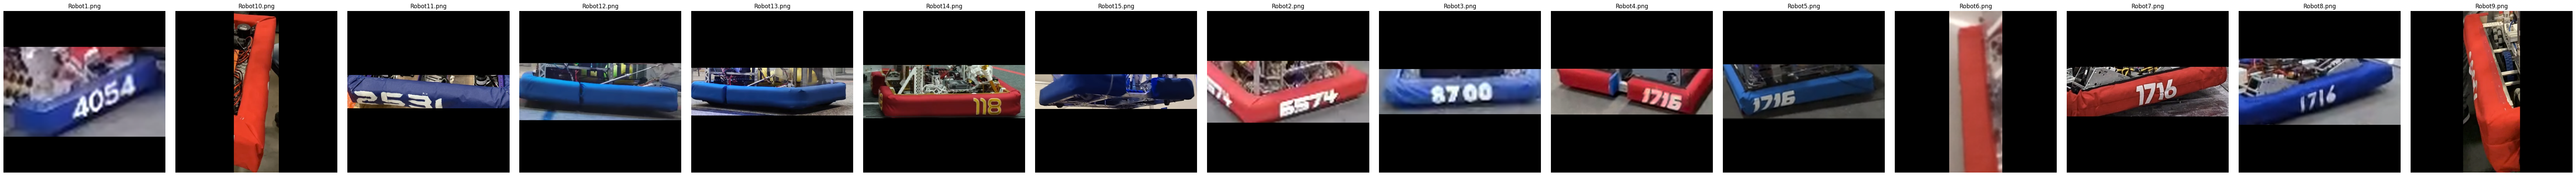

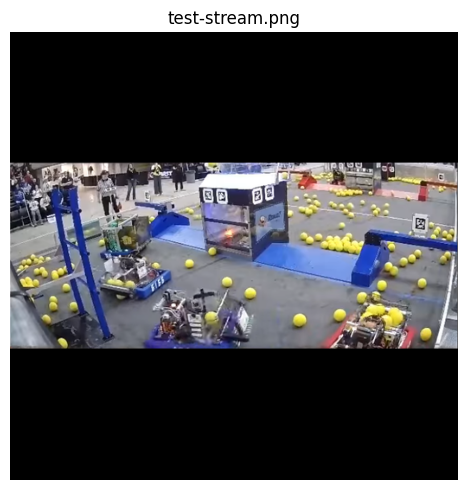

In [4]:
guide_paths = list_image_paths(CONFIG.guide_folder)
guide_images = load_rgb_images(
    guide_paths,
    image_size=CONFIG.image_size,
    pad_color=CONFIG.pad_color,
)
test_image = load_rgb_image(
    CONFIG.test_image,
    image_size=CONFIG.image_size,
    pad_color=CONFIG.pad_color,
)

print(f"Loaded {len(guide_images)} guide images")
for path in guide_paths:
    print(f"  {path}")

show_images(guide_images, titles=[path.name for path in guide_paths])
show_images([test_image], titles=[Path(CONFIG.test_image).name])


## Load model

`dinov2-large` is a strong default for dense matching without making the notebook as heavy as the giant checkpoint.


In [5]:
processor, model = load_model(CONFIG.model_id, DEVICE)
print("Model loaded")


Loading weights:   0%|          | 0/439 [00:00<?, ?it/s]

Model loaded


## Extract dense patch embeddings


In [6]:
all_images = [test_image, *guide_images]
all_embeddings = extract_patch_embeddings(
    all_images,
    processor=processor,
    model=model,
    device=DEVICE,
    batch_size=CONFIG.batch_size,
)

test_embeddings = all_embeddings[0]
guide_embeddings = all_embeddings[1:]
guide_bank = build_guide_memory_bank(guide_embeddings)

print(f"All embeddings:  {tuple(all_embeddings.shape)}")
print(f"Test embeddings: {tuple(test_embeddings.shape)}")
print(f"Guide bank:      {tuple(guide_bank.shape)}")


All embeddings:  (16, 1369, 1024)
Test embeddings: (1369, 1024)
Guide bank:      (20535, 1024)


## Score test patches against the guide bank

Each test patch is scored by the mean cosine similarity of its `top_k_matches` nearest guide patches.


In [7]:
patch_scores = compute_patch_similarity_map(
    test_embeddings=test_embeddings,
    guide_bank=guide_bank,
    top_k=CONFIG.top_k_matches,
)
heatmap = reshape_patch_scores(patch_scores)

print(f"Heatmap shape: {heatmap.shape}")


Heatmap shape: (37, 37)


## Visualise the result


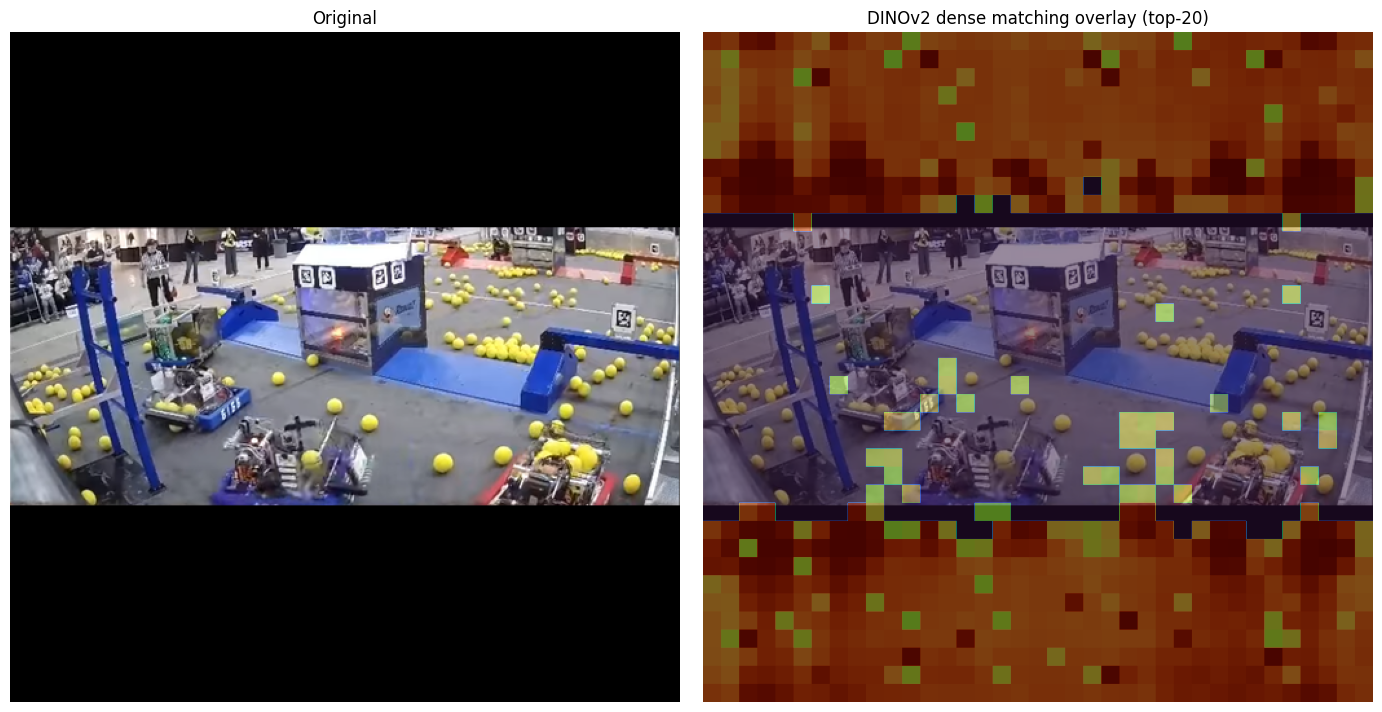

In [8]:
show_overlay(
    image=test_image,
    heatmap=heatmap*(heatmap > 0.5),
    title=f"DINOv2 dense matching overlay (top-{CONFIG.top_k_matches})",
) 
